# P7 · C　微调分类器：用 RoBERTa 检测 AI 生成文本

**负责人（C）**：YU ZIXUAN　G2605146C

本 notebook 完成方案 P7 中 C 部分的全部工作：

1. 加载 HC3 / MAGE / RAID（组内统一顺序：HC3 → MAGE → RAID → 新生成器 → 攻击后），按**分组**切成 train / val / test（同一问题或同一源文本的人类与 AI 文本不会同时出现在训练集和测试集，避免泄漏）；
2. 在本地 GPU 上微调 `roberta-base`（可在配置里换成 `microsoft/deberta-v3-small`），分别用 HC3、MAGE、RAID 和三者合并（ALL）训练 4 个模型；
3. 做「训练数据集 × 测试数据集」**泛化矩阵**（AUROC / macro-F1 / TPR@1%FPR），另加 RAID 带攻击子集（RAID-adv）测鲁棒性；
4. 导出统一格式的结果文件，检查 `predict()` 单文件接口，生成依赖包清单；
5. 留好 D（新生成器）、E（攻击版）测试集的推理入口，拿到 CSV 后各跑一次即可。

**标签约定**：`1 = AI 生成`，`0 = 人类`；`score` 为模型输出的 AI 概率（0–1），与组内其他检测器一致，便于统一算 AUROC。

| 产出文件 | 内容 |
|---|---|
| `P7_C_preds.csv` | 主模型（ALL）在各测试集上的逐条预测：`dataset,id,gold,pred,score` |
| `P7_C_preds_matrix.csv` | 4 个模型 × 全部测试集的逐条预测（多一列 `train_set`） |
| `P7_C_metrics.csv` | `dataset,method,config,metric,value` |
| `P7_C_matrix_auroc.csv` / `figs/P7_C_matrix_auroc.png` | 泛化矩阵 |
| `P7_C_auroc.csv` | 发给 E 的汇总行：`dataset,detector,auroc,f1,tpr_at_1fpr`（两位小数） |
| `models/ALL/` | 主模型权重，用 `P7_C_upload_hf.py` 以 fp16 上传到 Hugging Face |
| `requirements/P7_C.txt` | 依赖包与版本号（第 10 节自动生成） |

前端接口 `P7_C_predict.py`（仓库根目录）只负责按名字加载模型和 `predict()`，不含训练代码。

## 0. 配置
显存不够（如 6 GB）时把 `batch_size` 改成 8、`grad_accum` 改成 2；想要更长上下文把 `max_len` 改为 512（训练时间约翻倍）。

In [1]:
import os, re, json, math, time, random, hashlib, gc, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, accuracy_score
from functools import partial
from tqdm import tqdm as _tqdm
tqdm = partial(_tqdm, mininterval=30, ascii=True)  # 文本进度条，命令行（papermill）运行时也能看到

CFG = {
    "model_name": "roberta-base",     # 备选: "microsoft/deberta-v3-small"
    "max_len": 256,
    "batch_size": 16,
    "grad_accum": 1,
    "lr": 2e-5,
    "epochs": 2,
    "warmup_ratio": 0.06,
    "weight_decay": 0.01,
    "seed": 42,
    "n_train": 6000,                  # 每个数据集的训练样本数（人类 / AI 各一半）
    "n_val": 1000,
    "n_test": 1000,                   # 与组内约定一致：每个测试集 1000 条
    "min_chars": 50,                  # 过短文本不要
    "raid_attacks": ["none"],         # RAID 训练 / 主测试只用未攻击文本；带攻击的另成 RAID-adv
    "threshold": 0.5,
    "force_retrain": True,            # True：每次都重新训练（提交版要显示完整训练过程）；改成 False 可复用已训练模型
}
TRAIN_SETS = ["HC3", "MAGE", "RAID", "ALL"]
METHOD = CFG["model_name"].split("/")[-1] + "-ft"

ROOT = Path.cwd()
CACHE = ROOT / "data_cache"; CACHE.mkdir(exist_ok=True)
MODELS = ROOT / "models";    MODELS.mkdir(exist_ok=True)
FIGS = ROOT / "figs";        FIGS.mkdir(exist_ok=True)


def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed(CFG["seed"])

## 1. 环境检查

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    prop = torch.cuda.get_device_properties(0)
    print(f"GPU: {prop.name}  显存 {prop.total_memory / 1024**3:.1f} GB")
    # Ampere(30 系) 及以后用 bf16，更稳；更老的卡用 fp16 + GradScaler
    AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
    USE_AMP = True
else:
    print("⚠ 没检测到 CUDA，将使用 CPU（会非常慢）。请确认安装的是 CUDA 版 PyTorch。")
    AMP_DTYPE, USE_AMP = torch.float32, False
print("torch", torch.__version__, "| 混合精度:", AMP_DTYPE if USE_AMP else "关闭")

GPU: NVIDIA GeForce RTX 5070 Laptop GPU  显存 11.9 GB
torch 2.7.1+cu128 | 混合精度: torch.bfloat16


## 2. 数据

| 名称 | 来源 | 切分方式 |
|---|---|---|
| HC3 | `Hello-SimpleAI/HC3` 的 `all.jsonl`（英文，人类 vs ChatGPT 回答同一问题） | 按**问题**分组哈希切分 80/10/10 |
| MAGE | `yaful/MAGE`（27 个 LLM × 10 个领域；**原始标签 0 = AI、1 = 人类，这里翻转成 1 = AI**） | 用官方 train / validation / test；测试集按组内约定 `shuffle(seed=42).select(range(1000))` |
| RAID | `liamdugan/raid` train（HF 自动转换的 parquet 前段，约 227 万条） | 按**源文本**（`source_id`）分组哈希切分 80/10/10 |
| RAID-adv | 同上，`attack != none` 的测试组样本 | 只做测试 |

HC3、RAID 的切分只取决于分组键的 MD5 哈希，和抽样顺序无关，所以每次运行、每个人运行结果都一样。
训练 / 验证集人类 / AI 各占一半；MAGE 测试集按约定直接抽 1000 条，不做平衡。抽好的数据会缓存到 `data_cache/*.csv`，之后重跑不再下载。
第一次构建 RAID 会下载约 2.4 GB 的 parquet 分片（缓存在 HuggingFace 缓存目录），之后不再下载。

> 如果组里的约定文档给了别的加载代码，只需要改 `build_hc3 / build_mage / build_raid` 三个函数，保证返回同样的列即可。

In [3]:
def bucket(group_key) -> str:
    """确定性切分：MD5 哈希取模，10% test、10% val、80% train。"""
    h = int(hashlib.md5(str(group_key).encode("utf-8")).hexdigest(), 16) % 10
    return "test" if h == 0 else ("val" if h == 1 else "train")


def clean_text(t) -> str:
    return t.strip() if isinstance(t, str) else ""


def balanced_sample(df: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """人类 / AI 各取 n/2 条。"""
    parts = []
    for lab in (0, 1):
        sub = df[df["label"] == lab]
        k = n // 2
        if len(sub) < k:
            print(f"  ⚠ label={lab} 只有 {len(sub)} 条，少于需要的 {k} 条")
        parts.append(sub.sample(n=min(k, len(sub)), random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)


def split_by_pool(df: pd.DataFrame, seed: int) -> dict:
    df = df[df["text"].str.len() >= CFG["min_chars"]].drop_duplicates("text")
    n = {"train": CFG["n_train"], "val": CFG["n_val"], "test": CFG["n_test"]}
    return {s: balanced_sample(df[df["pool"] == s], n[s], seed) for s in n}


# ---------- HC3 ----------
def build_hc3() -> dict:
    from huggingface_hub import hf_hub_download
    path = hf_hub_download("Hello-SimpleAI/HC3", "all.jsonl", repo_type="dataset")
    rows = []
    with open(path, encoding="utf-8") as f:
        for qi, line in enumerate(f):
            if not line.strip():
                continue
            r = json.loads(line)
            g = f"hc3-q{qi}"
            for lab, key, tag in ((0, "human_answers", "h"), (1, "chatgpt_answers", "c")):
                for j, t in enumerate(r.get(key) or []):
                    rows.append({"id": f"{g}-{tag}{j}", "group": g, "text": clean_text(t),
                                 "label": lab, "domain": r.get("source", "")})
    df = pd.DataFrame(rows)
    df["pool"] = df["group"].map(bucket)
    return split_by_pool(df, CFG["seed"])


# ---------- MAGE ----------
def build_mage() -> dict:
    from datasets import load_dataset
    ds = load_dataset("yaful/MAGE")

    def to_df(d, split):
        df = d.to_pandas()
        if "orig_idx" not in df:
            df["orig_idx"] = np.arange(len(df))
        df["id"] = [f"mage-{split}-{i}" for i in df["orig_idx"]]
        df["text"] = df["text"].map(clean_text)
        df["label"] = 1 - df["label"].astype(int)        # MAGE: 0 = AI, 1 = 人类 → 翻转成 1 = AI
        df["domain"] = df["src"].astype(str)
        return df

    def train_like(d, split, n):
        df = to_df(d, split)
        df = df[df["text"].str.len() >= CFG["min_chars"]].drop_duplicates("text")
        return balanced_sample(df, n, CFG["seed"])

    test = ds["test"].add_column("orig_idx", list(range(len(ds["test"]))))
    test = test.shuffle(seed=CFG["seed"]).select(range(CFG["n_test"]))   # 与组内约定的加载代码一致
    return {"train": train_like(ds["train"], "train", CFG["n_train"]),
            "val": train_like(ds["validation"], "val", CFG["n_val"]),
            "test": to_df(test, "test").reset_index(drop=True)}


# ---------- RAID ----------
def cluster_pick(cand: pd.DataFrame, n: int, rng, n_clusters: int = 40) -> pd.DataFrame:
    """先随机挑 parquet row group，再在组内随机取行：
    既保证样本来自足够多的 (生成器, 领域) 区块，又不用把 RAID 整个下载下来。"""
    if len(cand) <= n:
        if len(cand) < n:
            print(f"  ⚠ RAID 候选只有 {len(cand)} 条，少于需要的 {n} 条")
        return cand
    grouped = cand.groupby(["file", "rg"])
    keys = list(grouped.groups.keys())
    rng.shuffle(keys)
    cap = max(1, math.ceil(n / min(len(keys), n_clusters)))
    out, total = [], 0
    for k in keys:
        g = grouped.get_group(k)
        take = g.sample(n=min(cap, len(g)), random_state=int(rng.integers(1_000_000_000)))
        out.append(take)
        total += len(take)
        if total >= n:
            break
    res = pd.concat(out)
    if len(res) < n:
        rest = cand.drop(index=res.index)
        res = pd.concat([res, rest.sample(n=n - len(res), random_state=0)])
    return res.iloc[:n]


def build_raid() -> dict:
    import pyarrow.parquet as pq
    from huggingface_hub import snapshot_download

    # 整块下载 parquet 分片（多线程、断点续传、缓存在 HF 缓存目录，比远程按列读快得多）
    print("RAID: 下载 parquet 分片（约 2.4 GB，只第一次）…")
    local = Path(snapshot_download("liamdugan/raid", repo_type="dataset", revision="refs/convert/parquet",
                                   allow_patterns=["raid/*train/*.parquet"], max_workers=8))
    files = sorted(str(p) for p in local.glob("raid/*train/*.parquet"))
    if not files:
        raise RuntimeError("没有找到 RAID 的 parquet 分片")
    print(f"RAID: {len(files)} 个分片，读取元数据列 …")

    meta_cols = ["id", "source_id", "model", "attack", "domain"]
    metas = []
    for fi, path in enumerate(tqdm(files, desc="RAID 元数据")):
        pf = pq.ParquetFile(path)
        t = pf.read(columns=meta_cols).to_pandas()
        sizes = [pf.metadata.row_group(i).num_rows for i in range(pf.num_row_groups)]
        t["file"] = fi
        t["rg"] = np.repeat(np.arange(len(sizes)), sizes)
        t["row"] = np.concatenate([np.arange(n) for n in sizes])
        metas.append(t)
    meta = pd.concat(metas, ignore_index=True)
    meta["label"] = (meta["model"] != "human").astype(int)
    meta["group"] = meta["source_id"].fillna(meta["id"]).astype(str)
    meta["pool"] = meta["group"].map(bucket)
    print("RAID 元数据:", len(meta), "行；人类", int((meta.label == 0).sum()), "行")

    rng = np.random.default_rng(CFG["seed"])
    clean = meta["attack"].isin(CFG["raid_attacks"])
    want = {"train": CFG["n_train"], "val": CFG["n_val"], "test": CFG["n_test"]}
    picks = []
    for split, n in want.items():
        for lab in (0, 1):
            cand = meta[clean & (meta["pool"] == split) & (meta["label"] == lab)]
            picks.append(cluster_pick(cand, n // 2, rng).assign(split=split))
    for lab in (0, 1):  # 带攻击的测试集
        cand = meta[~clean & (meta["pool"] == "test") & (meta["label"] == lab)]
        picks.append(cluster_pick(cand, CFG["n_test"] // 2, rng).assign(split="test_adv"))
    sel = pd.concat(picks)

    # 只读被抽中的 row group 的正文列
    text = pd.Series(index=sel.index, dtype=object)
    for fi, sub in tqdm(sel.groupby("file"), desc="RAID 正文"):
        pf = pq.ParquetFile(files[fi])
        for rg, g in sub.groupby("rg"):
            col = pf.read_row_group(int(rg), columns=["generation"]).column(0).to_pylist()
            text.loc[g.index] = [col[r] for r in g["row"]]
    sel["text"] = text.map(clean_text)
    sel["id"] = "raid-" + sel["id"].astype(str)
    sel["domain"] = sel["domain"].astype(str) + "/" + sel["model"].astype(str) + "/" + sel["attack"].astype(str)
    sel = sel[sel["text"].str.len() >= CFG["min_chars"]]
    out = {}
    for split in ["train", "val", "test", "test_adv"]:
        out[split] = sel[sel["split"] == split].sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
    return out


def build_raid_stream() -> dict:
    """备用方案：流式读取 train.csv 前段（文件按生成器/领域排序，分布会有偏，仅在 parquet 方案失败时使用）。"""
    from datasets import load_dataset
    print("⚠ 回退到流式读取 RAID train.csv，样本分布会偏向文件前段的领域和生成器")
    ds = load_dataset("liamdugan/raid", split="train", streaming=True)
    need = {(s, l): (CFG[f"n_{s}"] // 2) for s in ("train", "val", "test") for l in (0, 1)}
    need.update({("test_adv", 0): CFG["n_test"] // 2, ("test_adv", 1): CFG["n_test"] // 2})
    got = {k: [] for k in need}
    rng = random.Random(CFG["seed"])
    for i, r in enumerate(tqdm(ds, desc="RAID stream")):
        if all(len(got[k]) >= need[k] for k in need) or i > 4_000_000:
            break
        t = clean_text(r["generation"])
        if len(t) < CFG["min_chars"] or rng.random() > 0.2:  # 稀疏抽样，减少相邻行聚集
            continue
        lab = int(r["model"] != "human")
        pool = bucket(r["source_id"] or r["id"])
        split = pool if r["attack"] in CFG["raid_attacks"] else ("test_adv" if pool == "test" else None)
        if split and len(got[(split, lab)]) < need[(split, lab)]:
            got[(split, lab)].append({"id": f"raid-{r['id']}", "text": t, "label": lab,
                                      "domain": f"{r['domain']}/{r['model']}/{r['attack']}"})
    out = {}
    for split in ["train", "val", "test", "test_adv"]:
        rows = got[(split, 0)] + got[(split, 1)]
        out[split] = pd.DataFrame(rows).sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
    return out


# ---------- 统一入口 + 缓存 ----------
SPLITS = {"HC3": ["train", "val", "test"], "MAGE": ["train", "val", "test"],
          "RAID": ["train", "val", "test", "test_adv"]}
KEEP_COLS = ["id", "text", "label", "domain"]


def prepare(name: str) -> dict:
    paths = {s: CACHE / f"{name}_{s}.csv" for s in SPLITS[name]}
    if all(p.exists() for p in paths.values()):
        out = {s: pd.read_csv(p, keep_default_na=False) for s, p in paths.items()}
    else:
        print(f"== 构建 {name} ==")
        if name == "HC3":
            out = build_hc3()
        elif name == "MAGE":
            out = build_mage()
        else:
            try:
                out = build_raid()
            except Exception as e:  # noqa: BLE001
                print("parquet 方案失败:", repr(e))
                out = build_raid_stream()
        for s, d in out.items():
            d[KEEP_COLS].to_csv(paths[s], index=False, encoding="utf-8")
    for s in out:
        out[s] = out[s][KEEP_COLS].copy()
        out[s]["label"] = out[s]["label"].astype(int)
        out[s]["text"] = out[s]["text"].astype(str)
    return out


DATA = {name: prepare(name) for name in ["HC3", "MAGE", "RAID"]}

# 测试集：名字就是写进结果文件的 dataset 列
TEST_SETS = {"HC3": DATA["HC3"]["test"], "MAGE": DATA["MAGE"]["test"],
             "RAID": DATA["RAID"]["test"], "RAID-adv": DATA["RAID"]["test_adv"]}

In [4]:
def describe(d: pd.DataFrame) -> dict:
    words = d["text"].str.split().str.len()
    return {"n": len(d), "AI 占比": round(d["label"].mean(), 3),
            "人类中位词数": int(words[d.label == 0].median()) if (d.label == 0).any() else None,
            "AI 中位词数": int(words[d.label == 1].median()) if (d.label == 1).any() else None}


stats = pd.DataFrame({f"{n}/{s}": describe(d) for n, sp in DATA.items() for s, d in sp.items()}).T
stats.to_csv("P7_C_data_stats.csv", encoding="utf-8")
stats

,n,AI 占比,人类中位词数,AI 中位词数
HC3/train,6000.0,0.500,86.0,173.0
HC3/val,1000.0,0.500,83.0,177.0
HC3/test,1000.0,0.500,92.0,174.0
MAGE/train,6000.0,0.500,125.0,112.0
MAGE/val,1000.0,0.500,111.0,127.0
MAGE/test,1000.0,0.476,125.0,146.0
RAID/train,5998.0,0.500,237.0,230.0
RAID/val,999.0,0.499,238.0,179.0
RAID/test,1000.0,0.500,242.0,222.0
RAID/test_adv,1000.0,0.500,244.0,247.0


上表里「人类中位词数」和「AI 中位词数」差得越多，模型越可能只靠长度这类表面特征就分对——这是解读 HC3 上高分时需要注意的地方。

## 3. 微调
用纯 PyTorch 训练循环（不依赖 `Trainer`，避免 transformers 版本差异）：AdamW + 线性 warmup/衰减、混合精度、梯度裁剪；每个 epoch 末在验证集上算 AUROC，保留最好的一版。

In [5]:
def make_loader(df: pd.DataFrame, tok, batch_size: int, shuffle: bool) -> DataLoader:
    texts = df["text"].tolist()
    labels = df["label"].astype(int).tolist()

    def collate(idx):
        enc = tok([texts[i] for i in idx], truncation=True, max_length=CFG["max_len"],
                  padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor([labels[i] for i in idx], dtype=torch.long)
        return enc

    g = torch.Generator()
    g.manual_seed(CFG["seed"])
    # Windows + notebook 下多进程 DataLoader 容易出错，num_workers 固定为 0
    return DataLoader(list(range(len(texts))), batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate, generator=g, num_workers=0)


@torch.no_grad()
def score_texts(model, tok, texts, batch_size: int = 64) -> np.ndarray:
    """返回每条文本的 AI 概率。按长度排序后分批，减少 padding。"""
    model.eval()
    texts = list(texts)
    order = np.argsort([len(t) for t in texts])[::-1]
    scores = np.zeros(len(texts), dtype=np.float32)
    for i in range(0, len(texts), batch_size):
        idx = order[i:i + batch_size]
        enc = tok([texts[j] for j in idx], truncation=True, max_length=CFG["max_len"],
                  padding=True, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(**enc).logits
        scores[idx] = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()
    return scores


def make_scaler():
    enabled = USE_AMP and AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):  # 老版本 torch
        return torch.cuda.amp.GradScaler(enabled=enabled)


def train_model(train_df: pd.DataFrame, val_df: pd.DataFrame, tag: str) -> Path:
    out_dir = MODELS / tag
    # 训练数据的指纹：数据或底座模型变了就自动重训，没变就直接复用
    data_sig = hashlib.md5(("|".join(sorted(train_df["id"])) + CFG["model_name"]).encode("utf-8")).hexdigest()
    log_path = out_dir / "train_log.json"
    if (out_dir / "config.json").exists() and log_path.exists() and not CFG["force_retrain"]:
        old_sig = json.loads(log_path.read_text(encoding="utf-8")).get("data_sig", data_sig)
        if old_sig == data_sig:
            print(f"[{tag}] 已有用同样数据训练的模型，跳过训练（如需重训把 force_retrain 设为 True）")
            return out_dir
        print(f"[{tag}] 训练数据变了，重新训练")
    set_seed(CFG["seed"])
    tok = AutoTokenizer.from_pretrained(CFG["model_name"])
    model = AutoModelForSequenceClassification.from_pretrained(
        CFG["model_name"], num_labels=2,
        id2label={0: "human", 1: "ai"}, label2id={"human": 0, "ai": 1},
    ).to(DEVICE)

    loader = make_loader(train_df, tok, CFG["batch_size"], shuffle=True)
    no_decay = ("bias", "LayerNorm.weight", "layernorm", "layer_norm")
    params = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
         "weight_decay": CFG["weight_decay"]},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
         "weight_decay": 0.0},
    ]
    opt = torch.optim.AdamW(params, lr=CFG["lr"])
    steps_per_epoch = math.ceil(len(loader) / CFG["grad_accum"])
    total = steps_per_epoch * CFG["epochs"]
    warm = int(CFG["warmup_ratio"] * total)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(1, warm) if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler = make_scaler()

    history, best, t0 = [], -1.0, time.time()
    for ep in range(CFG["epochs"]):
        model.train()
        run_loss, n_seen = 0.0, 0
        bar = tqdm(loader, desc=f"[{tag}] epoch {ep + 1}/{CFG['epochs']}")
        for step, batch in enumerate(bar):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = model(**batch).loss / CFG["grad_accum"]
            scaler.scale(loss).backward()
            if (step + 1) % CFG["grad_accum"] == 0 or step + 1 == len(loader):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()
            run_loss += loss.item() * CFG["grad_accum"]
            n_seen += 1
            if step % 20 == 0:
                bar.set_postfix(loss=f"{run_loss / n_seen:.4f}")
        val_scores = score_texts(model, tok, val_df["text"])
        val_auc = roc_auc_score(val_df["label"], val_scores)
        history.append({"epoch": ep + 1, "train_loss": run_loss / n_seen, "val_auroc": float(val_auc),
                         "elapsed_min": (time.time() - t0) / 60})
        print(f"[{tag}] epoch {ep + 1}: loss={run_loss / n_seen:.4f}  val AUROC={val_auc:.4f}")
        if val_auc > best:
            best = val_auc
            model.save_pretrained(out_dir)
            tok.save_pretrained(out_dir)

    log = {"tag": tag, "cfg": CFG, "data_sig": data_sig, "n_train": len(train_df), "n_val": len(val_df),
           "best_val_auroc": best, "minutes": (time.time() - t0) / 60, "history": history}
    (out_dir / "train_log.json").write_text(json.dumps(log, indent=2, ensure_ascii=False), encoding="utf-8")
    (out_dir / "p7c_meta.json").write_text(json.dumps({
        "method": METHOD, "base_model": CFG["model_name"], "train_set": tag,
        "max_len": CFG["max_len"], "threshold": CFG["threshold"], "label_map": {"0": "human", "1": "ai"},
    }, indent=2), encoding="utf-8")
    del model, opt
    gc.collect()
    torch.cuda.empty_cache()
    return out_dir


def train_split(tag: str, split: str) -> pd.DataFrame:
    if tag == "ALL":
        return pd.concat([DATA[n][split] for n in ["HC3", "MAGE", "RAID"]], ignore_index=True)
    return DATA[tag][split]

In [6]:
MODEL_DIRS = {}
for tag in TRAIN_SETS:
    MODEL_DIRS[tag] = train_model(train_split(tag, "train"), train_split(tag, "val"), tag)

train_logs = pd.DataFrame([
    {k: v for k, v in json.loads((MODEL_DIRS[t] / "train_log.json").read_text(encoding="utf-8")).items()
     if k in ("tag", "n_train", "best_val_auroc", "minutes")}
    for t in TRAIN_SETS if (MODEL_DIRS[t] / "train_log.json").exists()
])
train_logs

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[HC3] epoch 1/2:   0%|          | 0/375 [00:00<?, ?it/s]

[HC3] epoch 1/2:   0%|          | 0/375 [00:00<?, ?it/s, loss=0.5793]

[HC3] epoch 1/2:   0%|          | 0/375 [00:04<?, ?it/s, loss=0.6783]

[HC3] epoch 1/2:   0%|          | 0/375 [00:07<?, ?it/s, loss=0.5580]

... (301 outputs left out)

[ALL] epoch 2/2: 100%|##########| 1125/1125 [03:22<00:00,  5.56it/s, loss=0.1051]

[ALL] epoch 2: loss=0.1050  val AUROC=0.9853


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,tag,n_train,best_val_auroc,minutes
0,HC3,6000,0.999874,2.270732
1,MAGE,6000,0.902012,2.205681
2,RAID,5998,0.996373,2.259420
3,ALL,17998,0.985301,6.900350


## 4. 泛化矩阵：每个模型 × 每个测试集

In [7]:
def tpr_at_fpr(y, s, target: float = 0.01) -> float:
    fpr, tpr, _ = roc_curve(y, s)
    ok = fpr <= target
    return float(tpr[ok].max()) if ok.any() else 0.0


def compute_metrics(y, s, thr: float) -> dict:
    y = np.asarray(y).astype(int)
    s = np.asarray(s, dtype=float)
    p = (s >= thr).astype(int)
    # 组内统一指标名：AUROC、F1（sklearn macro-F1）、TPR@1%FPR
    m = {}
    if len(np.unique(y)) == 2:
        m["AUROC"] = roc_auc_score(y, s)
    else:
        m["AUROC"] = float("nan")
    m["F1"] = f1_score(y, p, average="macro", zero_division=0)
    m["TPR@1%FPR"] = tpr_at_fpr(y, s, 0.01) if len(np.unique(y)) == 2 else float("nan")
    m["Accuracy"] = accuracy_score(y, p)
    return m


def load_trained(tag: str):
    tok = AutoTokenizer.from_pretrained(MODEL_DIRS[tag])
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIRS[tag]).to(DEVICE).eval()
    return tok, model


def evaluate_all(test_sets: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    pred_rows, metric_rows = [], []
    for tag in TRAIN_SETS:
        tok, model = load_trained(tag)
        for ds_name, d in test_sets.items():
            s = score_texts(model, tok, d["text"])
            thr = CFG["threshold"]
            pred_rows.append(pd.DataFrame({
                "train_set": tag, "dataset": ds_name, "id": d["id"].values,
                "gold": d["label"].values, "pred": (s >= thr).astype(int), "score": np.round(s, 6)}))
            for k, v in compute_metrics(d["label"], s, thr).items():
                metric_rows.append({"dataset": ds_name, "method": METHOD,
                                    "config": f"train={tag}", "metric": k, "value": round(float(v), 4)})
        del model
        torch.cuda.empty_cache()
    return pd.concat(pred_rows, ignore_index=True), pd.DataFrame(metric_rows)


preds_matrix, metrics = evaluate_all(TEST_SETS)
auroc = metrics[metrics.metric == "AUROC"].pivot(index="config", columns="dataset", values="value")
auroc = auroc.loc[[f"train={t}" for t in TRAIN_SETS], list(TEST_SETS)]
auroc

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

dataset,HC3,MAGE,RAID,RAID-adv
config,,,,
train=HC3,1.0000,0.6368,0.8226,0.7572
train=MAGE,0.9304,0.8833,0.9267,0.8484
train=RAID,0.9156,0.5785,0.9973,0.9210
train=ALL,1.0000,0.9004,0.9967,0.9304


In [8]:
tpr1 = metrics[metrics.metric == "TPR@1%FPR"].pivot(index="config", columns="dataset", values="value")
tpr1.loc[[f"train={t}" for t in TRAIN_SETS], list(TEST_SETS)]

dataset,HC3,MAGE,RAID,RAID-adv
config,,,,
train=HC3,1.000,0.0819,0.556,0.362
train=MAGE,0.572,0.4181,0.502,0.428
train=RAID,0.678,0.0147,0.964,0.066
train=ALL,0.998,0.4475,0.960,0.104


## 5. 写出统一格式文件
主模型 = 在 ALL（HC3+MAGE+RAID 合并）上训练的 `models/ALL/`，用于 `P7_C_preds.csv`、前端（上传 Hugging Face）和 D/E 的新测试集。
`P7_C_auroc.csv` 按 E 的汇总表格式（`dataset,detector,auroc,f1,tpr_at_1fpr`，两位小数，统一数据集顺序）直接发给 E。

In [9]:
MAIN = "ALL"
EXPORT = MODEL_DIRS[MAIN]                                   # 主模型目录，上传 Hugging Face 也用它
PREDS_COLS = ["dataset", "id", "gold", "pred", "score"]
SET_ORDER = ["HC3", "MAGE", "RAID", "NewGen", "Attack"]    # 组内统一顺序（RAID-adv 是 C 自己加的鲁棒性测试，不进汇总表）


def write_outputs(preds_matrix: pd.DataFrame, metrics: pd.DataFrame):
    preds_matrix.to_csv("P7_C_preds_matrix.csv", index=False, encoding="utf-8")
    preds_matrix[preds_matrix.train_set == MAIN][PREDS_COLS].to_csv("P7_C_preds.csv", index=False, encoding="utf-8")
    metrics.to_csv("P7_C_metrics.csv", index=False, encoding="utf-8")
    m = metrics[metrics.config == f"train={MAIN}"].pivot(index="dataset", columns="metric", values="value")
    fmt = lambda v: "" if pd.isna(v) else f"{v:.2f}"
    rows = [{"dataset": d, "detector": "C", "auroc": fmt(m.loc[d, "AUROC"]), "f1": fmt(m.loc[d, "F1"]),
             "tpr_at_1fpr": fmt(m.loc[d, "TPR@1%FPR"])} for d in SET_ORDER if d in m.index]
    pd.DataFrame(rows).to_csv("P7_C_auroc.csv", index=False, encoding="utf-8")
    return pd.DataFrame(rows)


auroc.to_csv("P7_C_matrix_auroc.csv", encoding="utf-8")
write_outputs(preds_matrix, metrics)

,dataset,detector,auroc,f1,tpr_at_1fpr
0,HC3,C,1.00,0.99,1.00
1,MAGE,C,0.90,0.76,0.45
2,RAID,C,1.00,0.97,0.96


## 6. 图：泛化矩阵热力图（放进幻灯片）

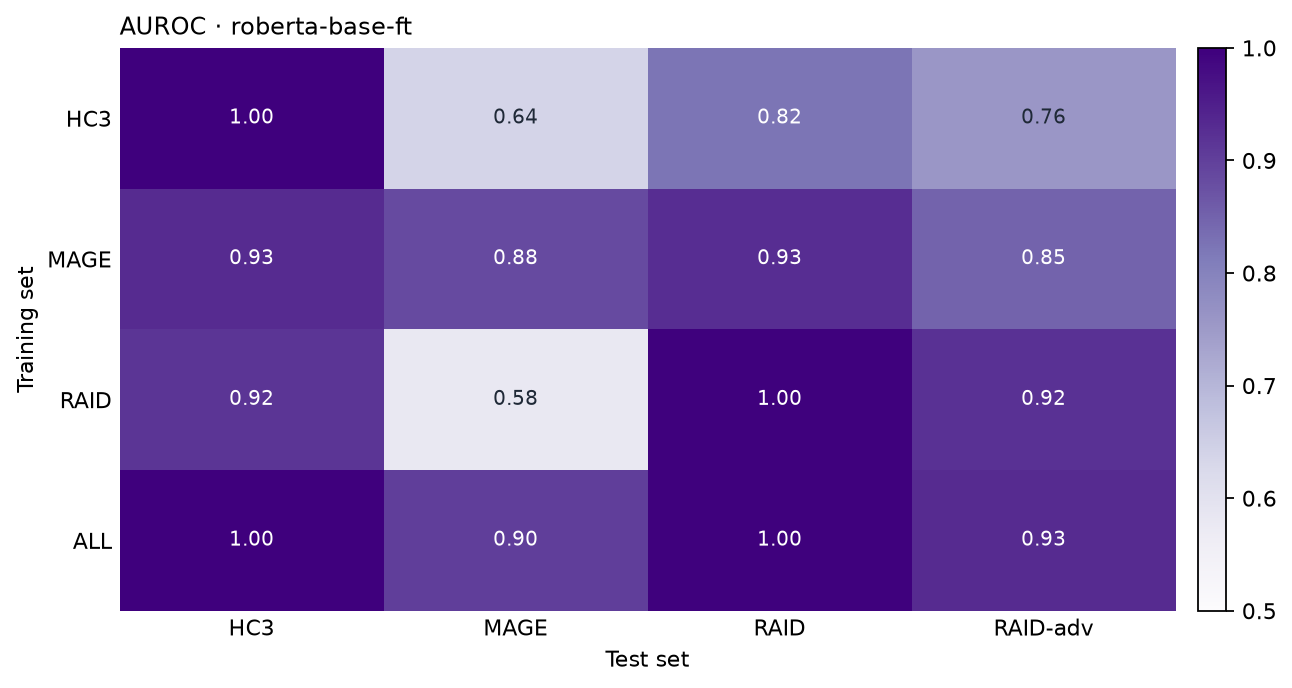

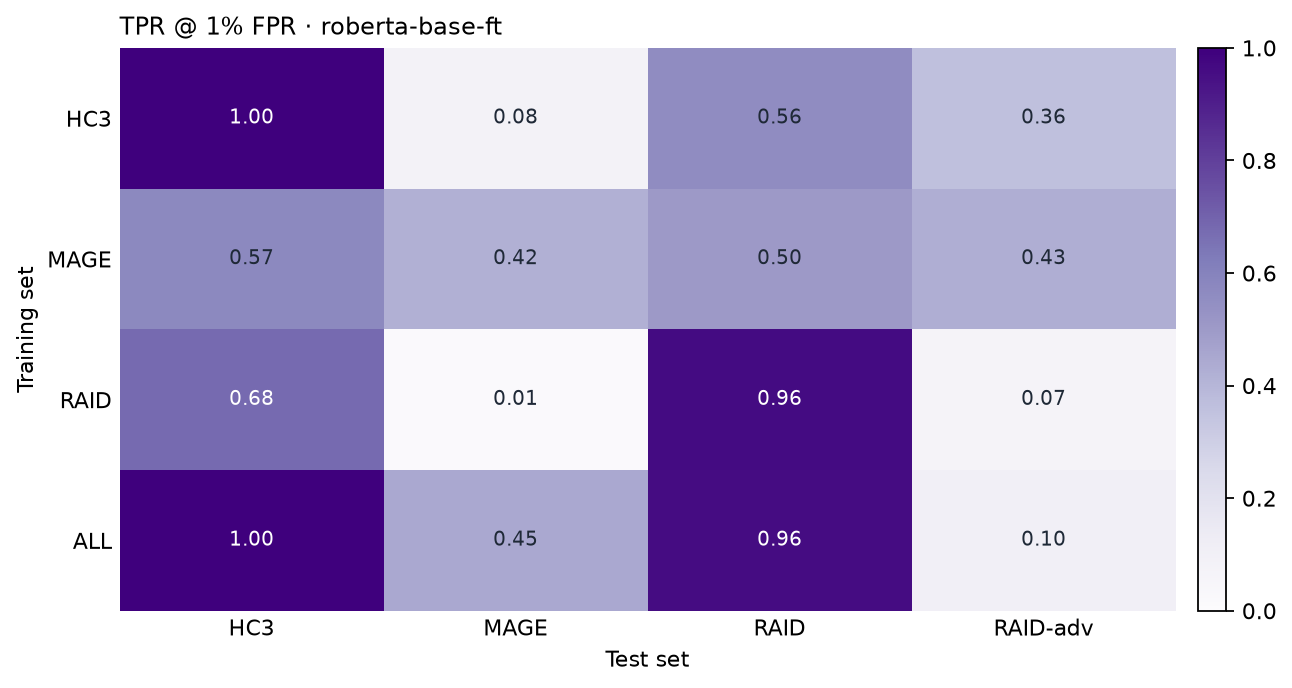

In [10]:
import matplotlib.pyplot as plt


def plot_matrix(tbl: pd.DataFrame, title: str, path: Path, vmin: float = 0.5):
    fig, ax = plt.subplots(figsize=(1.6 * tbl.shape[1] + 1.8, 0.75 * tbl.shape[0] + 1.4), dpi=160)
    im = ax.imshow(tbl.values.astype(float), cmap="Purples", vmin=vmin, vmax=1.0, aspect="auto")
    ax.set_xticks(range(tbl.shape[1]), [str(c) for c in tbl.columns])
    ax.set_yticks(range(tbl.shape[0]), [str(r).replace("train=", "") for r in tbl.index])
    ax.set_xlabel("Test set")
    ax.set_ylabel("Training set")
    ax.set_title(title, fontsize=11, loc="left")
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = float(tbl.values[i, j])
            if np.isnan(v):
                continue
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if v > vmin + 0.6 * (1 - vmin) else "#1f2937")
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_matrix(auroc, f"AUROC · {METHOD}", FIGS / "P7_C_matrix_auroc.png")
plot_matrix(tpr1.loc[auroc.index, auroc.columns], f"TPR @ 1% FPR · {METHOD}", FIGS / "P7_C_matrix_tpr1fpr.png", vmin=0.0)

## 7. 误判分析
重点看**人类文本被判成 AI**（假阳性）——在真实场景里这类误判代价最高。

In [11]:
main_preds = preds_matrix[preds_matrix.train_set == MAIN]
texts = pd.concat([d.assign(dataset=n) for n, d in TEST_SETS.items()])[["dataset", "id", "text"]]
err = main_preds.merge(texts, on=["dataset", "id"])

fp = err[(err.gold == 0) & (err.pred == 1)].sort_values("score", ascending=False)
fn = err[(err.gold == 1) & (err.pred == 0)].sort_values("score")
print("各测试集假阳性率（人类被判为 AI）：")
print((err[err.gold == 0].groupby("dataset")["pred"].mean()).round(3).to_string())
pd.set_option("display.max_colwidth", 200)
fp.head(8)[["dataset", "score", "text"]]

各测试集假阳性率（人类被判为 AI）：
dataset
HC3         0.018
MAGE        0.370
RAID        0.044
RAID-adv    0.152


,dataset,score,text
3861,RAID-adv,0.999891,"Leicester wing Austin Healey hopes to use Sunday's return Heineken Cup clash with Wasps as a further springboard to an England recall for the Six Nations. Healey, who won 51 caps prior to the 2003..."
3783,RAID-adv,0.999891,"A rise has been recorded in the number of students from south of the border applying to universities in Scotland. \n\nHowever, Lifelong Learning Minister Jim Wallace said that this would not resul..."
3723,RAID-adv,0.999891,"Software giant Microsoft is taking the plunge into the world of blogging. \n\nIt is launching a test service to allow people to publish blogs, or online journals, called MSN Spaces. \n\nMicrosoft ..."
3984,RAID-adv,0.999888,"Liverpool winger Harry Kewell is struggling to recover from his Achilles tendinitis problem and may not recover until March, claims his agent. \n\nKewell, 26, had hoped to play against Fulham last..."
3034,RAID-adv,0.999888,Manchester United striker Ruud van Nistelrooy may make his comeback after an Achilles tendon injury in the FA Cup fifth round tie at Everton on Saturday. He has been out of action for nearly three...
3075,RAID-adv,0.999888,"Leonardo DiCaprio, Jamie Foxx and Hilary Swank are among those due to attend this year's Oscar nominees luncheon on Monday. \n\nThey will join more than 100 nominees from the 24 Oscar categories a..."
3860,RAID-adv,0.999888,Sir Paul McCartney wowed fans with a live mini-concert at American football's Super Bowl - and avoided any Janet Jackson-style controversies. The 62-year-old sang Hey Jude and other Beatles songs ...
3766,RAID-adv,0.999888,"The China Three Gorges Project Corp is refusing to obey a government order to stop construction of one of its giant dams, the Chinese state press has said. The builder of the Three Gorges Dam is c..."


In [12]:
# 按文本长度分桶的 AUROC：短文本是不是更难？
err["words"] = err["text"].str.split().str.len()
err["len_bin"] = pd.cut(err["words"], [0, 50, 100, 200, 400, 100000],
                        labels=["≤50", "51–100", "101–200", "201–400", ">400"])
by_len = (err.groupby("len_bin", observed=True)
             .apply(lambda g: pd.Series({"n": len(g),
                                         "auroc": roc_auc_score(g.gold, g.score) if g.gold.nunique() == 2 else np.nan}))
             .round(3))
by_len

,n,auroc
len_bin,,
≤50,398.0,0.884
51–100,458.0,0.960
101–200,1277.0,0.980
201–400,1389.0,0.975
>400,478.0,0.964


## 8. D、E 的新测试集（拿到 CSV 后运行）
D 发来「新生成器」测试集、E 发来「攻击版」测试集后，把文件放进本文件夹，取消注释运行即可。
会用 4 个模型都推理一遍，并更新 `P7_C_preds.csv` / `P7_C_preds_matrix.csv` / `P7_C_metrics.csv` / `P7_C_auroc.csv`（同名数据集会被覆盖，可重复运行）。
CSV 只需要一列文本（text / generation / content / answer）和一列标签（label / gold / is_ai / y；1/0 或 "ai"/"human"）。

In [13]:
AI_WORDS = {"1", "ai", "machine", "generated", "llm", "true", "yes", "gpt"}
HUMAN_WORDS = {"0", "human", "false", "no"}


def _to_label(v) -> int:
    s = str(v).strip().lower()
    if s in AI_WORDS:
        return 1
    if s in HUMAN_WORDS:
        return 0
    return int(float(s) >= 0.5)


def run_external(csv_path, name: str, text_col: str | None = None, label_col: str | None = None):
    global preds_matrix, metrics
    df = pd.read_csv(csv_path, keep_default_na=False)
    cols = {c.lower(): c for c in df.columns}
    tc = text_col or next(cols[c] for c in ["text", "generation", "content", "answer"] if c in cols)
    lc = label_col or next(cols[c] for c in ["label", "gold", "is_ai", "y"] if c in cols)
    df = df[df[tc].astype(str).str.strip() != ""].reset_index(drop=True)
    ids = df[cols["id"]].astype(str) if "id" in cols else pd.Series([f"{name}-{i}" for i in range(len(df))])
    test = pd.DataFrame({"id": ids.values, "text": df[tc].astype(str).values, "label": df[lc].map(_to_label).values})
    p, m = evaluate_all({name: test})
    preds_matrix = pd.concat([preds_matrix[preds_matrix.dataset != name], p], ignore_index=True)
    metrics = pd.concat([metrics[metrics.dataset != name], m], ignore_index=True)
    write_outputs(preds_matrix, metrics)
    return m.pivot(index="config", columns="metric", values="value")


# run_external("P7_D_newgen_test.csv", name="NewGen")      # D：新生成器
# run_external("P7_E_attack_test.csv", name="Attack")      # E：改写 / 回译 / 错别字 / 同形字攻击

## 9. 检查 `predict()` 单文件接口
前端用的 `P7_C_predict.py` 默认按名字从 Hugging Face 下载模型；这里用环境变量指向本地的 `models/ALL/` 先测一遍。
返回格式按组内统一约定：`{"prob_ai": float, "label": "AI"/"Human", "extra": {...}}`。

In [14]:
import importlib, sys
for p in (ROOT, ROOT.parent):  # 仓库里 P7_C_predict.py 在根目录，notebook 在 notebooks/ 下
    if (p / "P7_C_predict.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
os.environ["P7_C_MODEL"] = str(EXPORT)
import P7_C_predict
importlib.reload(P7_C_predict)
sample_h = DATA["HC3"]["test"].query("label == 0")["text"].iloc[0]
sample_a = DATA["HC3"]["test"].query("label == 1")["text"].iloc[0]
for t in (sample_h, sample_a):
    r = P7_C_predict.predict(t)
    assert set(r) == {"prob_ai", "label", "extra"}
    print(r["label"], round(r["prob_ai"], 4), "|", t[:100].replace("\n", " "), "…")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Human 0.0003 | The fart from ur car spins a fan which give more air for your car to breathe and make more power to  …
AI 0.9999 | It's generally not a good idea to try to shoot someone with the goal of wounding them, rather than k …


## 10. 依赖包清单
记录本次实验实际用到的包和版本号，写到 `requirements/P7_C.txt`。

In [15]:
from importlib.metadata import version, PackageNotFoundError

PKGS = ["torch", "transformers", "datasets", "huggingface_hub", "safetensors", "tokenizers",
        "pyarrow", "pandas", "numpy", "scikit-learn", "matplotlib", "tqdm"]
lines = ["# P7 · C 微调分类器（Python " + ".".join(map(str, __import__("sys").version_info[:3])) + "）",
         "# torch 需装 CUDA 版：RTX 50 系显卡用 pip install torch==" + torch.__version__.split("+")[0]
         + " --index-url https://download.pytorch.org/whl/cu128"]
for pkg in PKGS:
    try:
        lines.append(f"{pkg}=={version(pkg).split('+')[0]}")
    except PackageNotFoundError:
        pass
(ROOT / "requirements").mkdir(exist_ok=True)
(ROOT / "requirements" / "P7_C.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

# P7 · C 微调分类器（Python 3.12.10）
# torch 需装 CUDA 版：RTX 50 系显卡用 pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cu128
torch==2.7.1
transformers==5.22.1
datasets==5.1.0
huggingface_hub==2.4.0
safetensors==0.8.0
tokenizers==0.23.3
pyarrow==26.0.1
pandas==3.1.1
numpy==2.5.4
scikit-learn==1.9.1
matplotlib==3.11.2
tqdm==4.70.1
